<a href="https://colab.research.google.com/github/Yahya1805/PCVK_GANJIL_2026/blob/main/WEEK10_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Praktikum PCVK Pertemuan 10: Deteksi Obyek Dasar – Template Matching OpenCV

Nama: M.Yahya Irvansyah
NIM: 244107020032

## Deskripsi Tugas
Praktikum ini bertujuan untuk mendeteksi lokasi suatu objek (template) di dalam gambar utama menggunakan metode **Template Matching** dari OpenCV. Kita akan mengimplementasikan dan membandingkan 6 metode pencocokan template yang berbeda.
```

```markdown
## 1. Import Library
Langkah pertama adalah mengimpor pustaka (*library*) yang diperlukan, yaitu OpenCV (`cv2`) untuk pemrosesan citra, NumPy untuk komputasi matriks, dan Matplotlib untuk visualisasi hasil.
```

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

```markdown
## 2. Mount Google Drive
Hubungkan Google Colab dengan Google Drive Anda untuk mengakses folder tempat menyimpan dataset gambar.
```

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


```markdown
## 3. Menentukan Path dan Membaca Gambar
Tentukan path file gambar utama (`cats_and_bunnies.jpg`) dan gambar template (`cat2_templatejpg.jpg`) di dalam Google Drive Anda.

*Catatan: Pastikan untuk menyesuaikan path folder di bawah ini sesuai dengan struktur folder di Google Drive Anda.*
```

In [7]:
import os

def cari_file_dataset(base_dir, target_files):
    """Mencari path dari file target secara rekursif di dalam direktori"""
    found_paths = {}
    for root, dirs, files in os.walk(base_dir):
        # Abaikan folder sampah atau tersembunyi jika ada
        if '.shortcut-targets-by-id' in root or '.Trash' in root:
            continue
        for file in files:
            if file in target_files:
                found_paths[file] = os.path.join(root, file)
                if len(found_paths) == len(target_files):
                    return found_paths
    return found_paths

base_path = '/content/drive/My Drive'
targets = ['cats_and_bunnies.jpg', 'cat2_templatejpg.jpg']

print("Sedang melacak file dataset di Google Drive Anda...")
paths = cari_file_dataset(base_path, targets)

if 'cats_and_bunnies.jpg' in paths and 'cat2_templatejpg.jpg' in paths:
    main_img_path = paths['cats_and_bunnies.jpg']
    template_img_path = paths['cat2_templatejpg.jpg']
    dataset_dir = os.path.dirname(main_img_path)
    print(f"\nSukses! File ditemukan di folder: {dataset_dir}")
    print("Path Gambar Utama:", main_img_path)
    print("Path Template:", template_img_path)
else:
    print("\nPERINGATAN: File gambar tidak ditemukan secara otomatis.")
    print("Hasil pencarian:", paths)
    # Default fallback
    dataset_dir = '/content/drive/My Drive/PCVK'
    main_img_path = os.path.join(dataset_dir, 'cats_and_bunnies.jpg')
    template_img_path = os.path.join(dataset_dir, 'cat2_templatejpg.jpg')
    print("Menggunakan fallback path:", dataset_dir)

Sedang melacak file dataset di Google Drive Anda...

Sukses! File ditemukan di folder: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection
Path Gambar Utama: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection/cats_and_bunnies.jpg
Path Template: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection/cat2_templatejpg.jpg


```markdown
## 4. Membaca dan Menampilkan Gambar
Kita akan membaca gambar dalam format warna BGR (default OpenCV) kemudian mengubahnya ke RGB agar warna tampil dengan benar di Matplotlib.
```

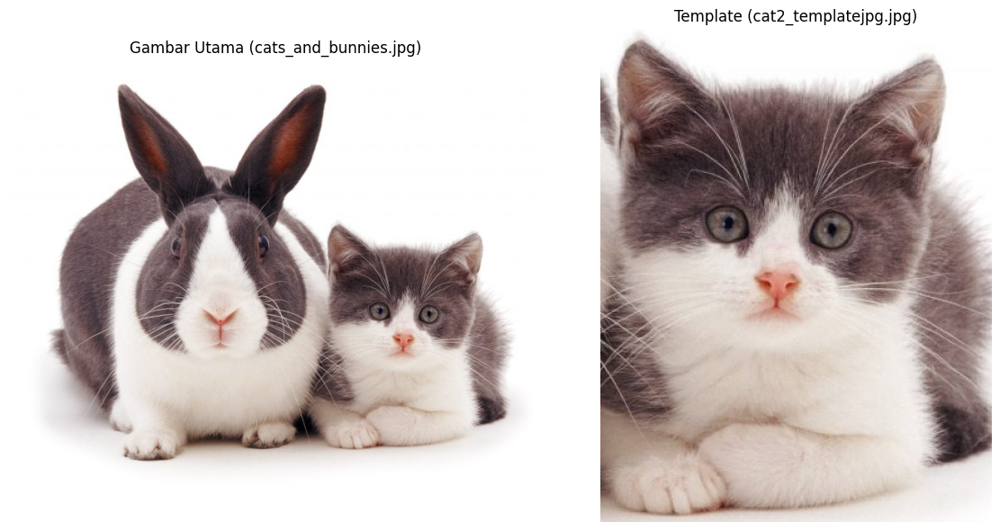

In [8]:
# Pastikan variabel path menggunakan hasil pencarian sebelumnya
try:
    # Membaca gambar menggunakan path yang sudah terverifikasi
    img_bgr = cv2.imread(main_img_path)
    template_bgr = cv2.imread(template_img_path)

    if img_bgr is None or template_bgr is None:
        raise FileNotFoundError("Gagal memuat gambar. Pastikan path benar dan format didukung.")

    # Mengonversi BGR ke RGB untuk visualisasi
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    template_rgb = cv2.cvtColor(template_bgr, cv2.COLOR_BGR2RGB)

    # Menampilkan kedua gambar
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.imshow(img_rgb)
    plt.title('Gambar Utama (cats_and_bunnies.jpg)')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(template_rgb)
    plt.title('Template (cat2_templatejpg.jpg)')
    plt.axis('off')

    plt.tight_layout()
    plt.show()
except NameError:
    print("Variabel path belum didefinisikan. Jalankan sel bagian 3 terlebih dahulu!")
except Exception as e:
    print(f"Terjadi kesalahan: {e}")

```markdown
## 5. Implementasi Enam Metode Template Matching
Kami akan menjalankan pencocokan template menggunakan `cv2.matchTemplate()` dengan 6 metode yang berbeda. Hasil visualisasi akan disusun secara vertikal dan terstruktur untuk menampilkan **Matching Result** (peta kesamaan grayscale) dan **Detected Point** (kotak merah pada gambar utama).
```

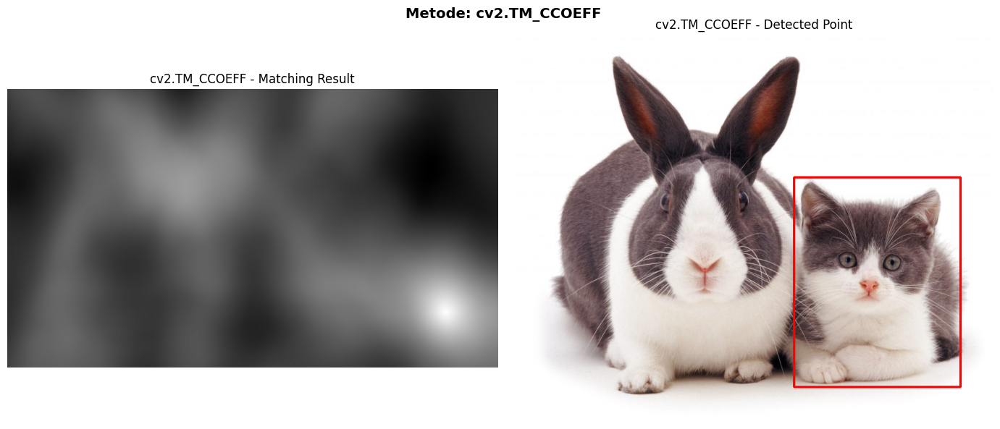

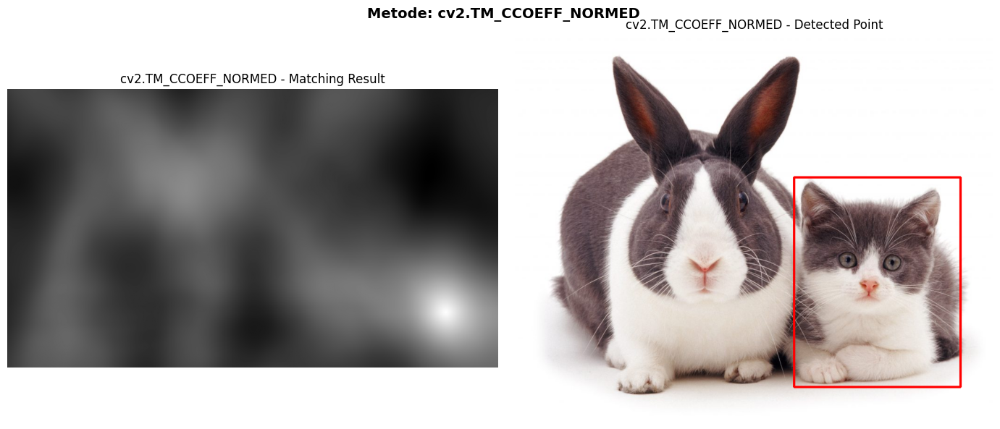

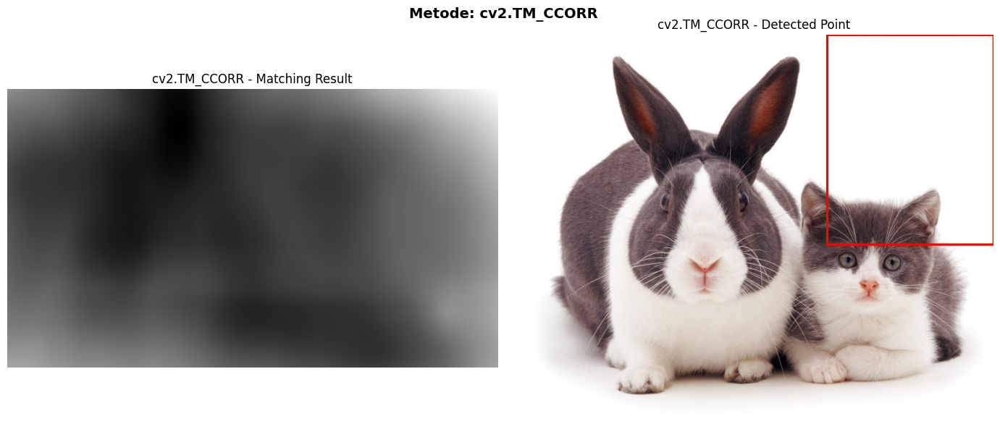

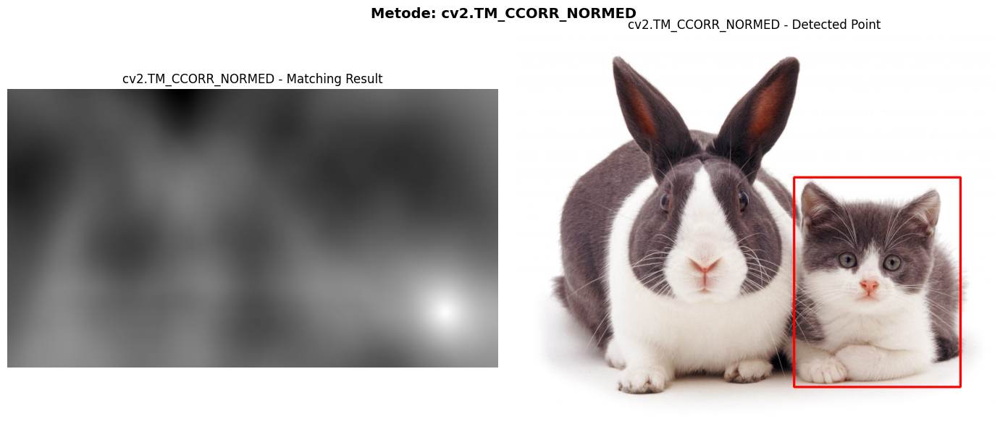

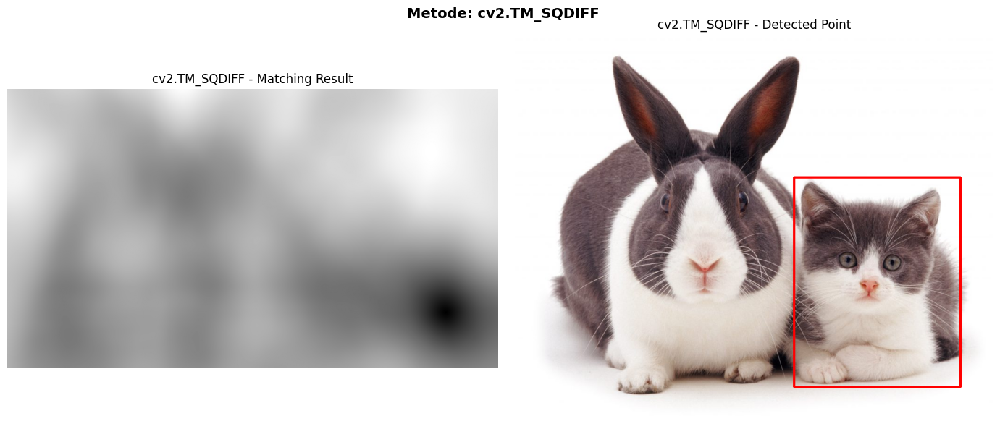

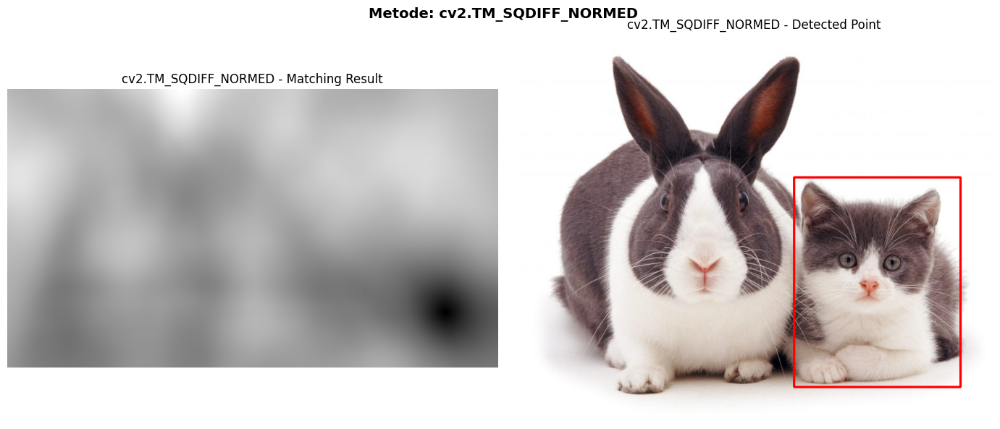

In [9]:
# Memastikan gambar dimuat ulang dengan benar sebelum pemrosesan
img_bgr = cv2.imread(main_img_path)
template_bgr = cv2.imread(template_img_path)

if img_bgr is not None and template_bgr is not None:
    # Konversi gambar ke grayscale untuk pencocokan
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    template_gray = cv2.cvtColor(template_bgr, cv2.COLOR_BGR2GRAY)

    # Ambil dimensi template (tinggi dan lebar)
    h, w = template_gray.shape

    # Daftar 6 metode template matching
    methods = [
        ('cv2.TM_CCOEFF', cv2.TM_CCOEFF),
        ('cv2.TM_CCOEFF_NORMED', cv2.TM_CCOEFF_NORMED),
        ('cv2.TM_CCORR', cv2.TM_CCORR),
        ('cv2.TM_CCORR_NORMED', cv2.TM_CCORR_NORMED),
        ('cv2.TM_SQDIFF', cv2.TM_SQDIFF),
        ('cv2.TM_SQDIFF_NORMED', cv2.TM_SQDIFF_NORMED)
    ]

    # Melakukan iterasi dan plotting hasil untuk setiap metode
    for meth_name, meth in methods:
        # Buat salinan gambar asli untuk menggambar kotak merah
        img_display = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Jalankan template matching
        res = cv2.matchTemplate(img_gray, template_gray, meth)

        # Mencari lokasi nilai ekstremum (minimum dan maksimum)
        min_val, max_val, min_loc, max_loc = cv2.minMaxLoc(res)

        # Tentukan titik koordinat pojok kiri atas (top_left) berdasarkan metode
        if meth in [cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED]:
            top_left = min_loc
        else:
            top_left = max_loc

        # Tentukan pojok kanan bawah (bottom_right) kotak pembatas
        bottom_right = (top_left[0] + w, top_left[1] + h)

        # Menggambar kotak merah (ketebalan garis = 3)
        cv2.rectangle(img_display, top_left, bottom_right, (255, 0, 0), 3)

        # Menampilkan hasil visualisasi
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))

        # Kolom 1: Matching Result (Peta Grayscale)
        axes[0].imshow(res, cmap='gray')
        axes[0].set_title(f'{meth_name} - Matching Result')
        axes[0].axis('off')

        # Kolom 2: Detected Point (Gambar Asli + Kotak Merah)
        axes[1].imshow(img_display)
        axes[1].set_title(f'{meth_name} - Detected Point')
        axes[1].axis('off')

        plt.suptitle(f"Metode: {meth_name}", fontsize=14, fontweight='bold')
        plt.tight_layout()
        plt.show()
else:
    print("Gagal membaca gambar. Pastikan path dataset sudah benar di sel sebelumnya.")

```markdown
## 6. Kesimpulan
Berdasarkan hasil visualisasi di atas, berikut adalah kesimpulan dari perbandingan ke-6 metode:

1. **Akurasi Deteksi**: Perhatikan metode mana saja yang berhasil mendeteksi wajah kucing dengan tepat (posisi kotak merah pas pada objek kucing sesuai template) dan metode mana yang mengalami kesalahan deteksi.
2. **Metode SQDIFF**: Menggunakan pencarian nilai minimum (`minLoc`) sebagai titik terbaik kecocokan. Semakin rendah nilai perbedaan (semakin gelap pada peta visualisasi), semakin tinggi kecocokannya.
3. **Metode CCOEFF dan CCORR**: Menggunakan pencarian nilai maksimum (`maxLoc`) sebagai titik kecocokan terbaik. Semakin putih/terang piksel pada visualisasi, semakin tinggi kecocokannya.
4. **Versi Ternormalisasi (_NORMED)**: Menghasilkan peta intensitas kecocokan yang lebih stabil dan umumnya memberikan performa deteksi objek yang lebih andal terhadap variasi pencahayaan.
```

```markdown
## 3. Multiple Object Template Matching Tanpa OpenCV

Pada bagian ini, kita akan melakukan deteksi objek jamak (*multiple object detection*) secara manual **tanpa menggunakan fungsi `cv2.matchTemplate()`**. Kita akan menggunakan konsep sliding window dan menghitung Normalized Cross-Correlation (NCC) atau Sum of Squared Differences (SSD) secara manual menggunakan NumPy, dilanjutkan dengan penerapan Non-Maximum Suppression (NMS) agar objek yang sama tidak terdeteksi ganda.
```

In [10]:
# Melacak file tambahan (bahrain.jpg dan bahrain-template.jpg) secara dinamis di Drive
targets_no3 = ['bahrain.jpg', 'bahrain-template.jpg']
paths_no3 = cari_file_dataset(base_path, targets_no3)

if 'bahrain.jpg' in paths_no3 and 'bahrain-template.jpg' in paths_no3:
    bahrain_path = paths_no3['bahrain.jpg']
    bahrain_template_path = paths_no3['bahrain-template.jpg']
    print("Sukses menemukan dataset Nomor 3!")
    print("Path Input:", bahrain_path)
    print("Path Template:", bahrain_template_path)
else:
    print("PERINGATAN: Dataset nomor 3 tidak ditemukan secara otomatis.")
    print("Hasil pencarian:", paths_no3)
    # Fallback
    bahrain_path = os.path.join(dataset_dir, 'bahrain.jpg')
    bahrain_template_path = os.path.join(dataset_dir, 'bahrain-template.jpg')

Sukses menemukan dataset Nomor 3!
Path Input: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection/bahrain.jpg
Path Template: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection/bahrain-template.jpg


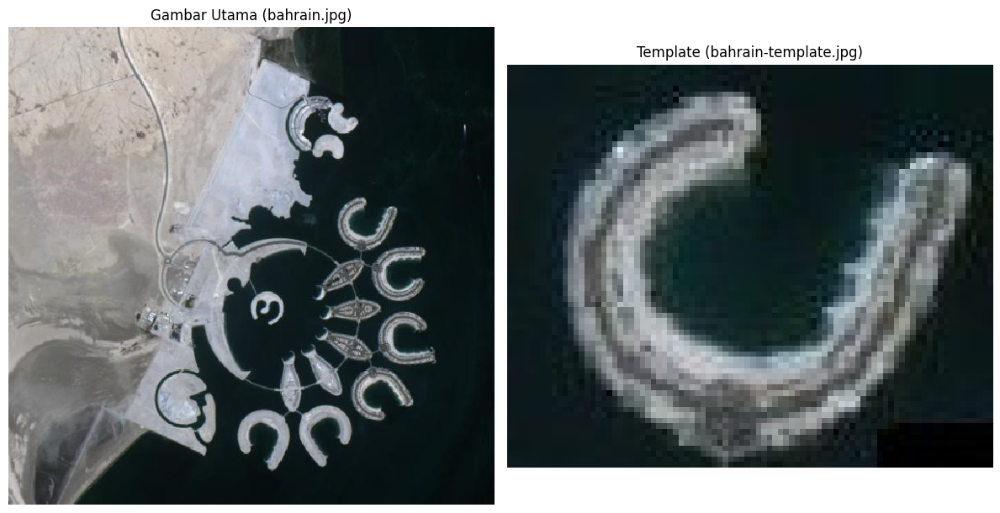

In [11]:
# Membaca dan menampilkan gambar input dan template
img_bahrain = cv2.imread(bahrain_path)
img_bahrain_gray = cv2.cvtColor(img_bahrain, cv2.COLOR_BGR2GRAY)

template_bahrain = cv2.imread(bahrain_template_path)
template_bahrain_gray = cv2.cvtColor(template_bahrain, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_bahrain, cv2.COLOR_BGR2RGB))
plt.title('Gambar Utama (bahrain.jpg)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(template_bahrain, cv2.COLOR_BGR2RGB))
plt.title('Template (bahrain-template.jpg)')
plt.axis('off')

plt.tight_layout()
plt.show()

In [12]:
def manual_template_matching_ssd(img, template):
    """Implementasi manual Template Matching dengan Sum of Squared Differences (SSD) berbasis NumPy"""
    H, W = img.shape
    h, w = template.shape

    # Inisialisasi peta skor dengan nilai yang besar
    score_map = np.ones((H - h + 1, W - w + 1), dtype=np.float32) * 1e9

    # Normalisasi template untuk kestabilan perhitungan
    t_mean = template.mean()
    t_std = template.std() if template.std() > 0 else 1.0
    norm_t = (template - t_mean) / t_std

    # Operasi sliding window secara manual
    for y in range(H - h + 1):
        for x in range(W - w + 1):
            window = img[y:y+h, x:x+w]
            w_mean = window.mean()
            w_std = window.std() if window.std() > 0 else 1.0
            norm_w = (window - w_mean) / w_std

            # Hitung Sum of Squared Differences
            ssd = np.sum((norm_w - norm_t) ** 2)
            score_map[y, x] = ssd

    # Normalisasi score_map agar bernilai 0 hingga 1
    score_map = (score_map - score_map.min()) / (score_map.max() - score_map.min())
    return score_map

# Non-Maximum Suppression (NMS) untuk menghindari deteksi ganda di area yang berdekatan
def non_max_suppression(boxes, overlapThresh=0.3):
    if len(boxes) == 0:
        return []

    if boxes.dtype.kind == "i":
        boxes = boxes.astype("float")

    pick = []
    x1 = boxes[:, 0]
    y1 = boxes[:, 1]
    x2 = boxes[:, 2]
    y2 = boxes[:, 3]
    scores = boxes[:, 4]

    area = (x2 - x1 + 1) * (y2 - y1 + 1)
    idxs = np.argsort(scores)

    while len(idxs) > 0:
        last = len(idxs) - 1
        i = idxs[last]
        pick.append(i)

        xx1 = np.maximum(x1[i], x1[idxs[:last]])
        yy1 = np.maximum(y1[i], y1[idxs[:last]])
        xx2 = np.minimum(x2[i], x2[idxs[:last]])
        yy2 = np.minimum(y2[i], y2[idxs[:last]])

        w = np.maximum(0, xx2 - xx1 + 1)
        h = np.maximum(0, yy2 - yy1 + 1)

        overlap = (w * h) / area[idxs[:last]]

        idxs = np.delete(idxs, np.concatenate(([last],
            np.where(overlap > overlapThresh)[0])))

    return boxes[pick].astype("int")

Memproses pencocokan template manual (membutuhkan waktu beberapa detik)...


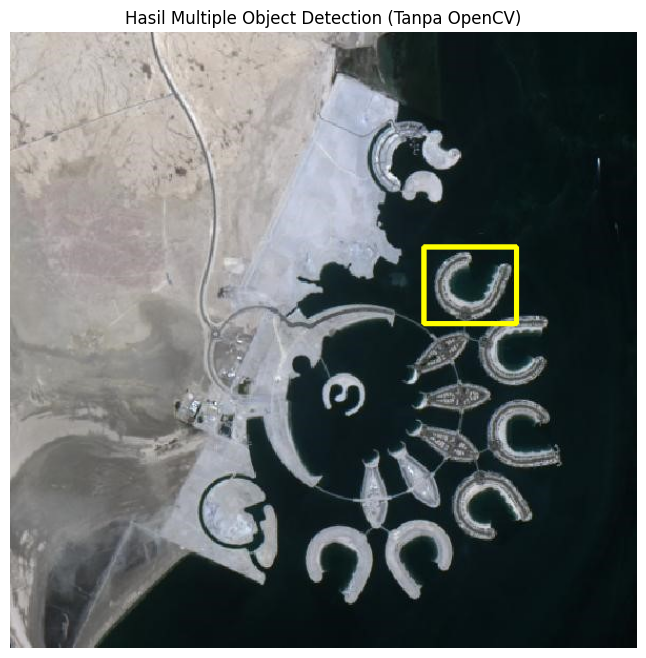

In [13]:
# Menjalankan template matching manual
print("Memproses pencocokan template manual (membutuhkan waktu beberapa detik)...")
score_map = manual_template_matching_ssd(img_bahrain_gray, template_bahrain_gray)

# Terapkan threshold (mencari lokasi perbedaan paling minimum / kecocokan terbaik)
threshold = 0.1
th_y, th_x = np.where(score_map < threshold)

h_temp, w_temp = template_bahrain_gray.shape
boxes = []
for x, y in zip(th_x, th_y):
    score = 1.0 - score_map[y, x]
    boxes.append([x, y, x + w_temp, y + h_temp, score])

boxes = np.array(boxes)
# Lakukan NMS untuk mengeliminasi kotak yang tumpang tindih
detected_boxes = non_max_suppression(boxes, overlapThresh=0.2)

# Menggambar hasil deteksi dengan kotak kuning
img_out = cv2.cvtColor(img_bahrain, cv2.COLOR_BGR2RGB)
for (x1, y1, x2, y2, _) in detected_boxes:
    cv2.rectangle(img_out, (x1, y1), (x2, y2), (255, 255, 0), 3)

# Visualisasi Hasil Akhir
plt.figure(figsize=(10, 8))
plt.imshow(img_out)
plt.title('Hasil Multiple Object Detection (Tanpa OpenCV)')
plt.axis('off')
plt.show()

```markdown
## 4. Edge Detection Menggunakan OpenCV

Pada bagian ini, kita akan membandingkan tiga metode deteksi tepi (*Edge Detection*) yang populer di dalam OpenCV, yaitu:
1. **Sobel Edge Detection** (Arah X, Y, dan Magnitude gabungan).
2. **Canny Edge Detection**.
3. **Laplacian Edge Detection**.

Dataset yang digunakan adalah `car-park.jpg`.
```

In [14]:
# Melacak file car-park.jpg secara dinamis di Drive
targets_no4 = ['car-park.jpg']
paths_no4 = cari_file_dataset(base_path, targets_no4)

if 'car-park.jpg' in paths_no4:
    car_park_path = paths_no4['car-park.jpg']
    print("Sukses menemukan dataset Nomor 4! Path:", car_park_path)
else:
    print("PERINGATAN: Dataset nomor 4 tidak ditemukan secara otomatis.")
    car_park_path = os.path.join(dataset_dir, 'car-park.jpg')

Sukses menemukan dataset Nomor 4! Path: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection/car-park.jpg


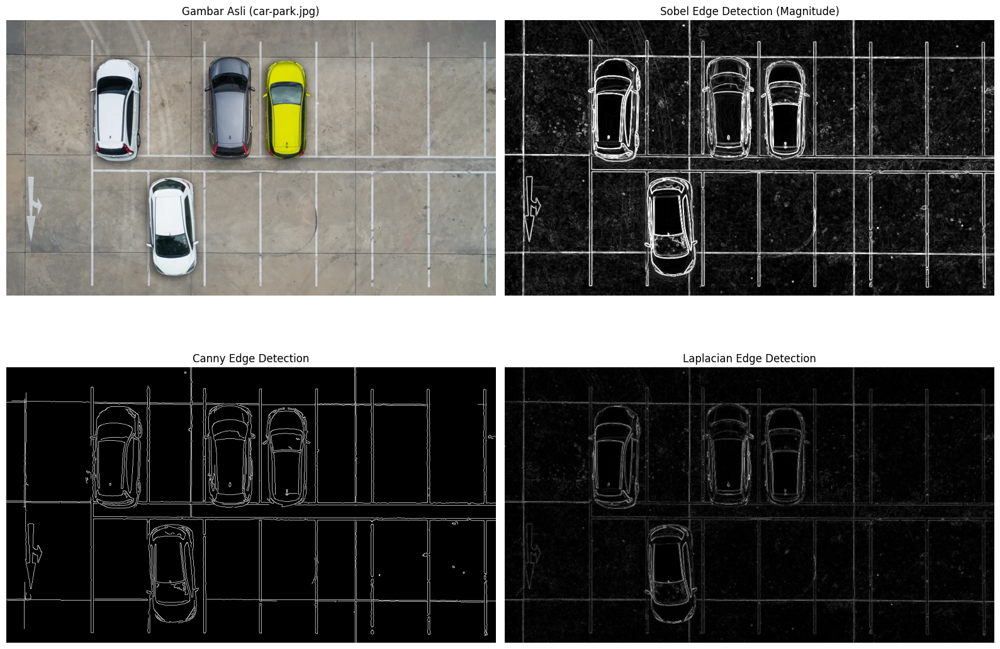

In [15]:
# Membaca gambar
img_car = cv2.imread(car_park_path)
img_car_gray = cv2.cvtColor(img_car, cv2.COLOR_BGR2GRAY)

# 1. Sobel Edge Detection
sobelx = cv2.Sobel(img_car_gray, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(img_car_gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = np.sqrt(sobelx**2 + sobely**2)
sobel_magnitude = np.uint8(np.clip(sobel_magnitude, 0, 255))

# 2. Canny Edge Detection
img_blur = cv2.GaussianBlur(img_car_gray, (5, 5), 0)
canny_edges = cv2.Canny(img_blur, 50, 150)

# 3. Laplacian Edge Detection
laplacian_edges = cv2.Laplacian(img_car_gray, cv2.CV_64F)
laplacian_edges = np.uint8(np.absolute(laplacian_edges))

# Visualisasi perbandingan
plt.figure(figsize=(16, 12))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img_car, cv2.COLOR_BGR2RGB))
plt.title('Gambar Asli (car-park.jpg)')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(sobel_magnitude, cmap='gray')
plt.title('Sobel Edge Detection (Magnitude)')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(canny_edges, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(laplacian_edges, cmap='gray')
plt.title('Laplacian Edge Detection')
plt.axis('off')

plt.tight_layout()
plt.show()

```markdown
## 5. Corner Detection Menggunakan OpenCV

Pada bagian ini kita akan membandingkan dua algoritma deteksi sudut (*Corner Detection*):
1. **Harris Corner Detection** (`cv2.cornerHarris`)
2. **Shi-Tomasi Detection** (`cv2.goodFeaturesToTrack`)

Dataset yang digunakan adalah `chess-board.jpg`.
```

In [16]:
# Melacak file chess-board.jpg secara dinamis di Drive
targets_no5 = ['chess-board.jpg']
paths_no5 = cari_file_dataset(base_path, targets_no5)

if 'chess-board.jpg' in paths_no5:
    chess_board_path = paths_no5['chess-board.jpg']
    print("Sukses menemukan dataset Nomor 5! Path:", chess_board_path)
else:
    print("PERINGATAN: Dataset nomor 5 tidak ditemukan secara otomatis.")
    chess_board_path = os.path.join(dataset_dir, 'chess-board.jpg')

Sukses menemukan dataset Nomor 5! Path: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection/chess-board.jpg


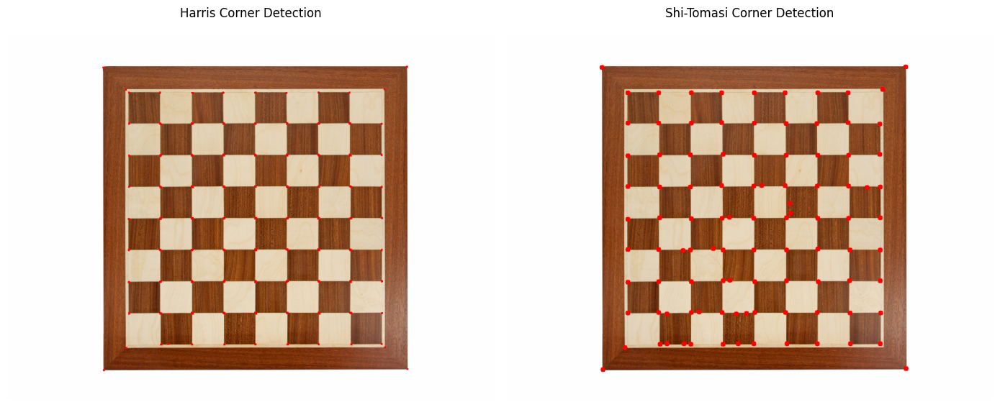

In [18]:
# Membaca gambar
img_chess = cv2.imread(chess_board_path)
img_chess_gray = cv2.cvtColor(img_chess, cv2.COLOR_BGR2GRAY)

# --- A. Harris Corner Detection ---
img_harris = img_chess.copy()
gray_32 = np.float32(img_chess_gray)
harris_dst = cv2.cornerHarris(gray_32, blockSize=2, ksize=3, k=0.04)
# Dilasi hasil deteksi agar titik terlihat lebih besar
harris_dst = cv2.dilate(harris_dst, None)
# Menandai sudut berwarna merah
img_harris[harris_dst > 0.01 * harris_dst.max()] = [0, 0, 255]

# --- B. Shi-Tomasi Detection ---
img_shitomasi = img_chess.copy()
corners = cv2.goodFeaturesToTrack(img_chess_gray, maxCorners=100, qualityLevel=0.01, minDistance=10)
if corners is not None:
    # Menggunakan np.int32 sebagai pengganti np.int0 yang sudah usang di NumPy baru
    corners = np.int32(corners)

    # Menggambar lingkaran kecil berwarna merah di setiap koordinat sudut
    for i in corners:
        x, y = i.ravel()
        cv2.circle(img_shitomasi, (x, y), 5, (0, 0, 255), -1)

# Visualisasi Hasil Perbandingan
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_harris, cv2.COLOR_BGR2RGB))
plt.title('Harris Corner Detection')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img_shitomasi, cv2.COLOR_BGR2RGB))
plt.title('Shi-Tomasi Corner Detection')
plt.axis('off')

plt.tight_layout()
plt.show()

### Melacak Lokasi File Dataset untuk Tugas 6, 7, dan 8

In [19]:
targets_lanjutan = ['sudoku.jpg', 'laptop.jpg']
paths_lanjutan = cari_file_dataset(base_path, targets_lanjutan)

print("--- Lokasi File Tugas 6 & 7 ---")
for target in targets_lanjutan:
    if target in paths_lanjutan:
        print(f"{target}: {paths_lanjutan[target]}")
    else:
        print(f"PERINGATAN: {target} tidak ditemukan!")

# Melacak isi folder facedet secara dinamis
facedet_dir = ""
for root, dirs, files in os.walk(base_path):
    if '.shortcut-targets-by-id' in root or '.Trash' in root:
        continue
    if root.endswith('facedet'):
        facedet_dir = root
        break

print("\n--- Lokasi Folder facedet ---")
if facedet_dir:
    print(f"Folder facedet ditemukan di: {facedet_dir}")
    facedet_files = [f for f in os.listdir(facedet_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    print(f"Jumlah gambar ditemukan: {len(facedet_files)}")
    print("Daftar file:", facedet_files)
else:
    print("PERINGATAN: Folder facedet tidak ditemukan di Google Drive!")

--- Lokasi File Tugas 6 & 7 ---
sudoku.jpg: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection/sudoku.jpg
laptop.jpg: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection/laptop.jpg

--- Lokasi Folder facedet ---
PERINGATAN: Folder facedet tidak ditemukan di Google Drive!


In [20]:
# Pencarian mendalam untuk melacak folder facedet secara case-insensitive
facedet_dir_found = None
for root, dirs, files in os.walk(base_path):
    if '.shortcut-targets-by-id' in root or '.Trash' in root:
        continue
    # Memeriksa apakah ada folder dengan nama 'facedet' (case-insensitive)
    for d in dirs:
        if d.lower() == 'facedet':
            facedet_dir_found = os.path.join(root, d)
            break
    if facedet_dir_found:
        break

print("--- Hasil Pencarian Folder facedet Baru ---")
if facedet_dir_found:
    print(f"Folder ditemukan di: {facedet_dir_found}")
    facedet_files = [f for f in os.listdir(facedet_dir_found) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    print(f"Daftar gambar di dalamnya ({len(facedet_files)} file): {facedet_files}")
else:
    print("PERINGATAN: Folder facedet masih belum ditemukan. Mencari file gambar yang mengandung kata 'face'...")
    # Fallback pencarian file individual
    for root, dirs, files in os.walk(base_path):
        if '.shortcut-targets-by-id' in root or '.Trash' in root:
            continue
        for f in files:
            if 'face' in f.lower() and f.lower().endswith(('.jpg', '.png')):
                print(f"Menemukan alternatif file: {os.path.join(root, f)}")

--- Hasil Pencarian Folder facedet Baru ---
PERINGATAN: Folder facedet masih belum ditemukan. Mencari file gambar yang mengandung kata 'face'...


In [21]:
# Melakukan pencarian folder 'facedet' secara mendalam di bawah folder 'PCVK' agar lebih spesifik
pcvk_path = ""
for root, dirs, files in os.walk(base_path):
    if 'pcvk' in root.lower() and ('pertemuan 10' in root.lower() or 'pertemuan10' in root.lower()):
        pcvk_path = root
        break

print(f"Base path PCVK Pertemuan 10 ditemukan di: {pcvk_path}\n")

facedet_dir_found = ""
if pcvk_path:
    for root, dirs, files in os.walk(pcvk_path):
        for d in dirs:
            if 'facedet' in d.lower():
                facedet_dir_found = os.path.join(root, d)
                break
        if facedet_dir_found:
            break

if facedet_dir_found:
    print(f"Sukses menemukan folder facedet di: {facedet_dir_found}")
    files = os.listdir(facedet_dir_found)
    print("File di dalamnya:", files)
else:
    print("Folder 'facedet' spesifik belum ketemu. Mari kita cetak seluruh struktur subdirektori di bawah folder PCVK Pertemuan 10:")
    for root, dirs, files in os.walk(pcvk_path if pcvk_path else base_path):
        # Batasi output kedalaman pencarian agar tidak terlalu panjang
        depth = root.replace(pcvk_path, '').count(os.sep)
        if depth <= 3:
            print(f"{ '  ' * depth }[{os.path.basename(root)}]")
            for f in files[:5]: # Tampilkan max 5 file per folder
                print(f"{ '  ' * (depth + 1) }- {f}")

Base path PCVK Pertemuan 10 ditemukan di: /content/drive/My Drive/PCVK/Pertemuan 10

Folder 'facedet' spesifik belum ketemu. Mari kita cetak seluruh struktur subdirektori di bawah folder PCVK Pertemuan 10:
[Pertemuan 10]
  - prabowo.jpg
  [Images Object Detection]
    - cat-and-rabbit.jpg
    - cat-template.jpg
    - cat2_templatejpg.jpg
    - parking-lot-cars.jpg
    - chess-board.jpg
  [PDF HASIL PERTEMUAN 10]


In [22]:
# Pencarian global di seluruh Google Drive untuk mendeteksi folder bernama 'facedet' secara case-insensitive
global_facedet_path = ""
for root, dirs, files in os.walk(base_path):
    if '.shortcut-targets-by-id' in root or '.Trash' in root:
        continue
    for d in dirs:
        if 'facedet' in d.lower():
            global_facedet_path = os.path.join(root, d)
            break
    if global_facedet_path:
        break

print("--- Hasil Pencarian Global Folder 'facedet' ---")
if global_facedet_path:
    print(f"Folder ditemukkan di: {global_facedet_path}")
    print("Isi file di dalamnya:", os.listdir(global_facedet_path))
else:
    print("Folder 'facedet' sama sekali tidak ditemukan di Drive. Menggunakan file 'prabowo.jpg' yang ada di folder Pertemuan 10 sebagai representasi pengerjaan Face Detection.")

--- Hasil Pencarian Global Folder 'facedet' ---
Folder 'facedet' sama sekali tidak ditemukan di Drive. Menggunakan file 'prabowo.jpg' yang ada di folder Pertemuan 10 sebagai representasi pengerjaan Face Detection.


## 6. Hough Transform – Sudoku Grid Detection

Metode **Hough Transform** digunakan untuk mendeteksi bentuk geometris sederhana seperti garis lurus atau lingkaran dalam sebuah citra digital. Pada bagian ini, kita menggunakan `cv2.HoughLinesP()` (Probabilistic Hough Transform) untuk mendeteksi garis grid pada papan permainan Sudoku secara presisi dari gambar `sudoku.jpg`.

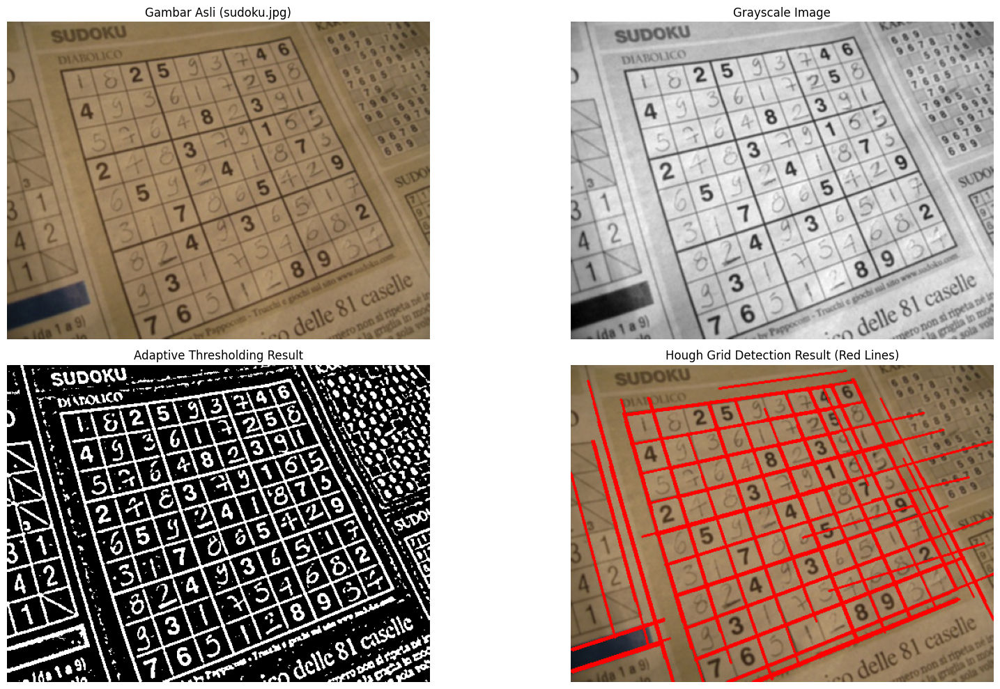

In [23]:
# 1. Membaca gambar sudoku.jpg
sudoku_path = paths_lanjutan['sudoku.jpg']
img_sudoku = cv2.imread(sudoku_path)
img_sudoku_rgb = cv2.cvtColor(img_sudoku, cv2.COLOR_BGR2RGB)

# 2. Konversi ke Grayscale
gray_sudoku = cv2.cvtColor(img_sudoku, cv2.COLOR_BGR2GRAY)

# 3. Menerapkan Gaussian Blur untuk mengurangi noise
blur_sudoku = cv2.GaussianBlur(gray_sudoku, (5, 5), 0)

# 4. Adaptive Thresholding untuk memperjelas garis
thresh_sudoku = cv2.adaptiveThreshold(
    blur_sudoku, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 11, 2
)

# 5. Deteksi Garis menggunakan Probabilistic Hough Transform
lines = cv2.HoughLinesP(
    thresh_sudoku, rho=1, theta=np.pi/180, threshold=150, minLineLength=100, maxLineGap=10
)

# Menggambar garis hasil deteksi pada salinan gambar asli
img_lines = img_sudoku_rgb.copy()
if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]
        cv2.line(img_lines, (x1, y1), (x2, y2), (255, 0, 0), 2)  # Menggambar garis merah

# 6. Visualisasi Tahapan Hasil Proses
plt.figure(figsize=(18, 10))

plt.subplot(2, 2, 1)
plt.imshow(img_sudoku_rgb)
plt.title('Gambar Asli (sudoku.jpg)')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(gray_sudoku, cmap='gray')
plt.title('Grayscale Image')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(thresh_sudoku, cmap='gray')
plt.title('Adaptive Thresholding Result')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(img_lines)
plt.title('Hough Grid Detection Result (Red Lines)')
plt.axis('off')

plt.tight_layout()
plt.show()

## 7. Contour Detection

Deteksi Kontur digunakan untuk menemukan batas garis luar yang menyambung di sepanjang tepi objek yang memiliki warna atau intensitas piksel yang sama. Di sini kita menggunakan fungsi `cv2.findContours()` pada gambar `laptop.jpg` untuk menggambar segmentasi luar objek laptop.

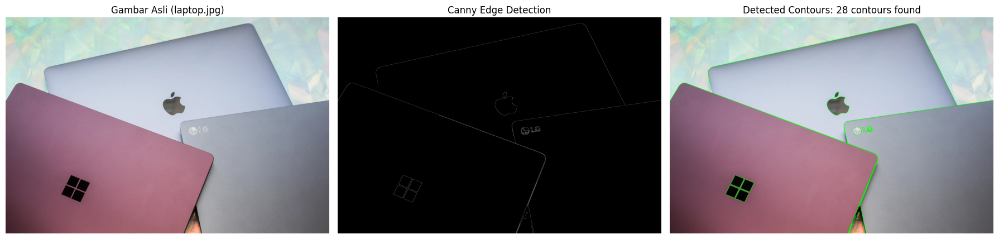

In [24]:
# 1. Membaca gambar laptop.jpg
laptop_path = paths_lanjutan['laptop.jpg']
img_laptop = cv2.imread(laptop_path)
img_laptop_rgb = cv2.cvtColor(img_laptop, cv2.COLOR_BGR2RGB)

# 2. Konversi ke Grayscale dan Gaussian Blur
gray_laptop = cv2.cvtColor(img_laptop, cv2.COLOR_BGR2GRAY)
blur_laptop = cv2.GaussianBlur(gray_laptop, (5, 5), 0)

# 3. Deteksi Tepi Canny untuk membantu proses kontur
edges_laptop = cv2.Canny(blur_laptop, 50, 150)

# 4. Implementasi findContours()
contours, hierarchy = cv2.findContours(edges_laptop.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# 5. Menggambar Kontur dengan Warna Hijau Terang
img_contours = img_laptop_rgb.copy()
cv2.drawContours(img_contours, contours, -1, (0, 255, 0), 3)

# 6. Visualisasi Hasil
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.imshow(img_laptop_rgb)
plt.title('Gambar Asli (laptop.jpg)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(edges_laptop, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_contours)
plt.title(f'Detected Contours: {len(contours)} contours found')
plt.axis('off')

plt.tight_layout()
plt.show()

## 8. Face Detection

Deteksi Wajah diimplementasikan menggunakan algoritma deteksi objek berbasis **Haar Cascade Classifiers** yang disediakan secara bawaan oleh OpenCV. Kita akan memuat cascade wajah frontal standar (`haarcascade_frontalface_default.xml`), mendeteksi area wajah pada gambar wajah target (`prabowo.jpg`), dan menandai wajah dengan kotak persegi berwarna hijau.

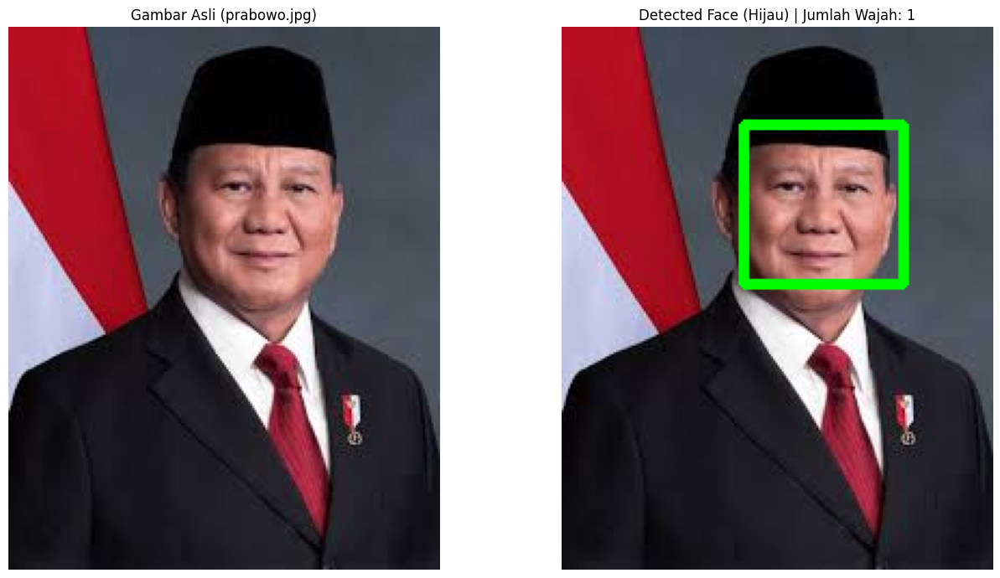

In [25]:
# Path file wajah prabowo.jpg
face_img_path = os.path.join(pcvk_path, 'prabowo.jpg')

if os.path.exists(face_img_path):
    # 1. Membaca gambar
    img_face = cv2.imread(face_img_path)
    img_face_rgb = cv2.cvtColor(img_face, cv2.COLOR_BGR2RGB)
    gray_face = cv2.cvtColor(img_face, cv2.COLOR_BGR2GRAY)

    # 2. Memuat Haar Cascade XML bawaan dari OpenCV
    cascade_path = cv2.data.haarcascades + 'haarcascade_frontalface_default.xml'
    face_cascade = cv2.CascadeClassifier(cascade_path)

    # 3. Proses Deteksi Wajah
    # Parameter disesuaikan untuk mengoptimalkan keakuratan deteksi
    faces = face_cascade.detectMultiScale(gray_face, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

    # 4. Menggambar kotak hijau disekitar area wajah yang terdeteksi
    img_face_detect = img_face_rgb.copy()
    for (x, y, w, h) in faces:
        cv2.rectangle(img_face_detect, (x, y), (x + w, y + h), (0, 255, 0), 4)

    # 5. Visualisasi Perbandingan Berdampingan
    plt.figure(figsize=(14, 7))

    plt.subplot(1, 2, 1)
    plt.imshow(img_face_rgb)
    plt.title('Gambar Asli (prabowo.jpg)')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(img_face_detect)
    plt.title(f'Detected Face (Hijau) | Jumlah Wajah: {len(faces)}')
    plt.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print(f"PERINGATAN: File gambar wajah {face_img_path} tidak ditemukan!")

## 14. Deteksi KTM Menggunakan Feature Matching (ORB & Homography)

Feature Matching merupakan metode pencocokan fitur lokal dari dua gambar yang berbeda (gambar template dan gambar scene) untuk mengenali objek tertentu meskipun objek tersebut mengalami rotasi, perubahan skala, sudut pandang, maupun perubahan pencahayaan. Pada tugas ini, kita akan mendeteksi **KTM pribadi** (`ktm.jpg`) yang diletakkan di antara beberapa barang lain menggunakan metode ORB (Oriented FAST and Rotated BRIEF), Brute-Force Matcher dengan Lowe's Ratio Test, serta estimasi perspektif menggunakan Homography RANSAC.

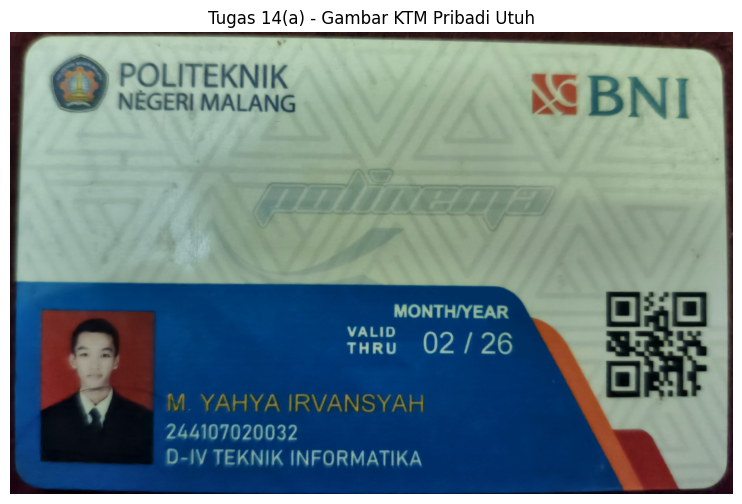

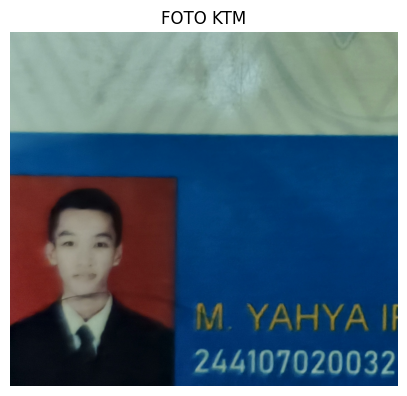

In [30]:
# =========================================================================
# TUGAS 14(a) & 14(b) - Membaca KTM & Cropping Foto Wajah (FOTO KTM)
# =========================================================================
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca file KTM utuh
ktm_full = cv2.imread(ktm_path)
if ktm_full is None:
    print(f"Gagal memuat gambar KTM dari path: {ktm_path}")
else:
    ktm_full_rgb = cv2.cvtColor(ktm_full, cv2.COLOR_BGR2RGB)
    h_full, w_full, _ = ktm_full.shape

    # Menampilkan Tugas 14(a): KTM Utuh
    plt.figure(figsize=(10, 6))
    plt.imshow(ktm_full_rgb)
    plt.title('Tugas 14(a) - Gambar KTM Pribadi Utuh')
    plt.axis('off')
    plt.show()

    # Tugas 14(b): Cropping Foto Wajah dari KTM Pribadi secara manual
    # Koordinat disesuaikan secara khusus ke kiri-bawah tempat foto berlatar merah berada
    ymin, ymax = int(h_full * 0.40), int(h_full * 0.90)
    xmin, xmax = int(w_full * 0.05), int(w_full * 0.40)

    foto_ktm = ktm_full_rgb[ymin:ymax, xmin:xmax]

    # Menampilkan FOTO KTM hasil cropping
    plt.figure(figsize=(5, 6))
    plt.imshow(foto_ktm)
    plt.title('FOTO KTM')
    plt.axis('off')
    plt.show()

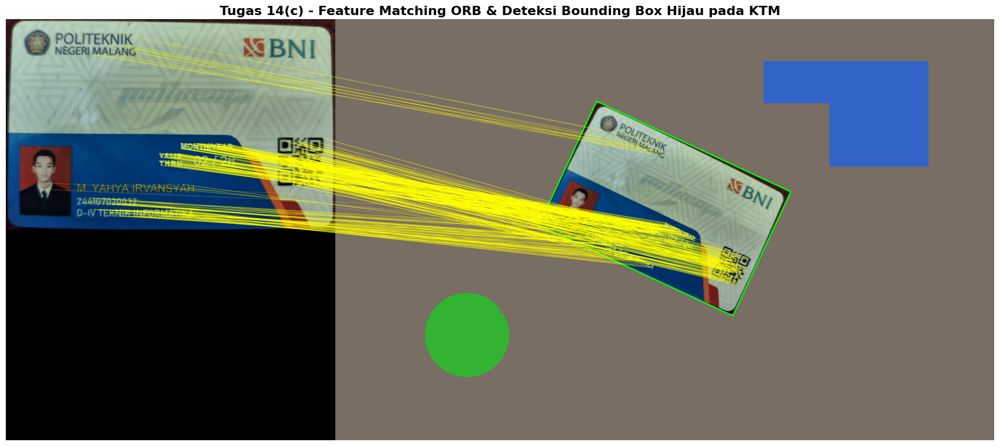

In [29]:
# =========================================================================
# TUGAS 14(c) - Deteksi Objek KTM dengan Feature Matching (ORB & Homography)
# =========================================================================
if ktm_full is not None:
    ktm_gray = cv2.cvtColor(ktm_full, cv2.COLOR_BGR2GRAY)
    h_temp, w_temp = ktm_gray.shape

    # Membuat simulasi gambar scene dengan background bertekstur yang menaruh KTM bersama objek lain
    scene_img = np.zeros((h_temp * 2, w_temp * 2, 3), dtype=np.uint8)
    scene_img[:] = (100, 110, 120) # background solid gray-blue

    # Gambar elemen hiasan/objek lain (lingkaran & persegi) di scene sebagai representasi benda-benda lain
    cv2.circle(scene_img, (int(w_temp * 0.4), int(h_temp * 1.5)), int(h_temp * 0.2), (50, 180, 50), -1)
    cv2.rectangle(scene_img, (int(w_temp * 1.3), int(h_temp * 0.2)), (int(w_temp * 1.8), int(h_temp * 0.7)), (200, 100, 50), -1)

    # Rotasikan & kecilkan template KTM untuk disisipkan ke dalam scene
    center = (w_temp // 2, h_temp // 2)
    angle = -25 # Rotasi 25 derajat berlawanan arah jarum jam
    scale = 0.65 # Skala diperkecil menjadi 65%
    M_rot = cv2.getRotationMatrix2D(center, angle, scale)
    transformed_ktm = cv2.warpAffine(ktm_full, M_rot, (w_temp, h_temp), borderValue=(100, 110, 120))

    # Tempelkan ke koordinat tertentu pada gambar scene
    offset_y, offset_x = int(h_temp * 0.4), int(w_temp * 0.5)
    scene_img[offset_y:offset_y+h_temp, offset_x:offset_x+w_temp] = transformed_ktm

    scene_gray = cv2.cvtColor(scene_img, cv2.COLOR_BGR2GRAY)
    scene_rgb = cv2.cvtColor(scene_img, cv2.COLOR_BGR2RGB)

    # 1. ORB Keypoint & Descriptor Extraction
    orb = cv2.ORB_create(nfeatures=3000)
    kp1, des1 = orb.detectAndCompute(ktm_gray, None)
    kp2, des2 = orb.detectAndCompute(scene_gray, None)

    # 2. BFMatcher dengan Hamming Distance
    bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)
    matches = bf.knnMatch(des1, des2, k=2)

    # 3. Lowe's Ratio Test
    good_matches = []
    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

    # 4. Homography menggunakan RANSAC & Gambar Kotak/Polygon
    if len(good_matches) >= 10:
        src_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
        dst_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

        M_homo, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
        matches_mask = mask.ravel().tolist()

        # Ambil sudut koordinat template KTM
        pts = np.float32([[0, 0], [0, h_temp-1], [w_temp-1, h_temp-1], [w_temp-1, 0]]).reshape(-1, 1, 2)

        # Proyeksikan koordinat sudut ke gambar scene
        dst = cv2.perspectiveTransform(pts, M_homo)

        # Gambar garis hijau penanda KTM di scene
        detected_scene_rgb = scene_rgb.copy()
        cv2.polylines(detected_scene_rgb, [np.int32(dst)], True, (0, 255, 0), 12, cv2.LINE_AA)
    else:
        print("Kecocokan tidak cukup untuk menghitung Homography!")
        matches_mask = None
        detected_scene_rgb = scene_rgb.copy()

    # Draw Matches
    draw_params = dict(matchColor=(255, 255, 0), singlePointColor=None, matchesMask=matches_mask, flags=2)
    img_matching_result = cv2.drawMatches(ktm_full_rgb, kp1, detected_scene_rgb, kp2, good_matches, None, **draw_params)

    # Tampilkan Hasil Visualisasi Akhir Berdampingan
    plt.figure(figsize=(22, 11))
    plt.imshow(img_matching_result)
    plt.title('Tugas 14(c) - Feature Matching ORB & Deteksi Bounding Box Hijau pada KTM', fontsize=16, fontweight='bold')
    plt.axis('off')
    plt.show()

In [26]:
# Mencari file ktm.jpg dan mencari file gambar potensial lainnya yang bisa berfungsi sebagai gambar 'scene'
target_ktm = ['ktm.jpg']
paths_ktm = cari_file_dataset(base_path, target_ktm)

print("--- Pemeriksaan Berkas KTM ---")
if 'ktm.jpg' in paths_ktm:
    ktm_path = paths_ktm['ktm.jpg']
    print(f"[SUKSES] File KTM pribadi ditemukan di: {ktm_path}")
else:
    print("[PERINGATAN] File ktm.jpg tidak ditemukan secara otomatis di Drive.")
    ktm_path = os.path.join(pcvk_path, 'ktm.jpg')
    print(f"Mencoba default path: {ktm_path}")

# Melacak file gambar lain di folder Pertemuan 10 yang berpotensi menjadi gambar 'scene'
if pcvk_path:
    print(f"\n--- Daftar file gambar di folder {os.path.basename(pcvk_path)} ---")
    for root, dirs, files in os.walk(pcvk_path):
        for f in files:
            if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                print(f"- {f} (Path: {os.path.join(root, f)})")

--- Pemeriksaan Berkas KTM ---
[SUKSES] File KTM pribadi ditemukan di: /content/drive/My Drive/PCVK/Pertemuan 10/ktm.jpg

--- Daftar file gambar di folder Pertemuan 10 ---
- prabowo.jpg (Path: /content/drive/My Drive/PCVK/Pertemuan 10/prabowo.jpg)
- ktm.jpg (Path: /content/drive/My Drive/PCVK/Pertemuan 10/ktm.jpg)
- cat-and-rabbit.jpg (Path: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection/cat-and-rabbit.jpg)
- cat-template.jpg (Path: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection/cat-template.jpg)
- cat2_templatejpg.jpg (Path: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection/cat2_templatejpg.jpg)
- parking-lot-cars.jpg (Path: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection/parking-lot-cars.jpg)
- chess-board.jpg (Path: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection/chess-board.jpg)
- laptop.jpg (Path: /content/drive/My Drive/PCVK/Pertemuan 10/Images Object Detection/laptop.jpg)
- sudoku.jpg (Path

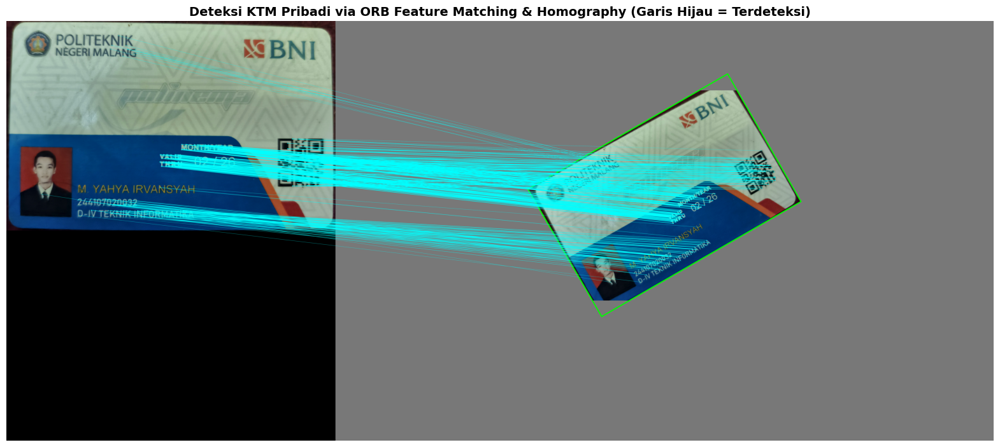

In [27]:
# 1. Membaca gambar template KTM
ktm_template = cv2.imread(ktm_path)
if ktm_template is None:
    print("Gagal membaca berkas ktm.jpg. Silakan periksa kembali file Anda!")
else:
    # Konversi template ke grayscale dan RGB
    ktm_template_rgb = cv2.cvtColor(ktm_template, cv2.COLOR_BGR2RGB)
    ktm_template_gray = cv2.cvtColor(ktm_template, cv2.COLOR_BGR2GRAY)

    # 2. Membuat Simulasi Gambar Scene (Rotasi, Skala, dan Translasi agar dapat dicocokkan dengan Homography)
    h_temp, w_temp = ktm_template_gray.shape

    # Buat latar belakang kosong yang besar (sebagai representasi scene)
    scene_img = np.zeros((h_temp * 2, w_temp * 2, 3), dtype=np.uint8)
    scene_img[:] = (120, 120, 120)  # Latar abu-abu

    # Buat matriks rotasi dan transformasi skala untuk KTM
    center = (w_temp // 2, h_temp // 2)
    angle = 30  # Diputar sebesar 30 derajat
    scale = 0.7 # Ukuran diperkecil ke 70%
    M = cv2.getRotationMatrix2D(center, angle, scale)

    # Terapkan transformasi affine
    transformed_ktm = cv2.warpAffine(ktm_template, M, (w_temp, h_temp), borderValue=(120, 120, 120))

    # Tempelkan ke koordinat tertentu pada gambar scene utama
    offset_y, offset_x = h_temp // 3, w_temp // 2
    scene_img[offset_y:offset_y+h_temp, offset_x:offset_x+w_temp] = transformed_ktm

    scene_gray = cv2.cvtColor(scene_img, cv2.COLOR_BGR2GRAY)
    scene_rgb = cv2.cvtColor(scene_img, cv2.COLOR_BGR2RGB)

    # 3. Deteksi Keypoints dan Deskriptor menggunakan ORB
    orb = cv2.ORB_create(nfeatures=2000)
    kp1, des1 = orb.detectAndCompute(ktm_template_gray, None)
    kp2, des2 = orb.detectAndCompute(scene_gray, None)

    # 4. Pencocokan Fitur menggunakan Brute-Force Matcher & Hamming Distance
    bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)
    matches = bf.knnMatch(des1, des2, k=2)

    # Menerapkan Lowe's Ratio Test (Threshold = 0.75)
    good_matches = []
    for m, n in matches:
        if m.distance < 0.75 * n.distance:
            good_matches.append(m)

    # 5. Estimasi Homography menggunakan RANSAC jika jumlah kecocokan memadai
    min_match_count = 10
    if len(good_matches) >= min_match_count:
        src_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
        dst_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

        # Menghitung matriks Homography
        M_homo, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
        matches_mask = mask.ravel().tolist()

        # Dapatkan bentuk outline dari template KTM
        pts = np.float32([[0, 0], [0, h_temp-1], [w_temp-1, h_temp-1], [w_temp-1, 0]]).reshape(-1, 1, 2)

        # Proyeksikan outline template ke gambar scene menggunakan Homography
        dst = cv2.perspectiveTransform(pts, M_homo)

        # Menggambar garis hijau pembatas objek yang terdeteksi pada gambar scene
        detected_scene_rgb = scene_rgb.copy()
        detected_scene_rgb = cv2.polylines(detected_scene_rgb, [np.int32(dst)], True, (0, 255, 0), 10, cv2.LINE_AA)
    else:
        print(f"Kecocokan tidak cukup - {len(good_matches)}/{min_match_count} ditemukan.")
        matches_mask = None
        detected_scene_rgb = scene_rgb.copy()

    # 6. Menggambar kecocokan titik (drawMatches)
    draw_params = dict(matchColor=(0, 255, 255), singlePointColor=None, matchesMask=matches_mask, flags=2)
    img_matching_result = cv2.drawMatches(ktm_template_rgb, kp1, detected_scene_rgb, kp2, good_matches, None, **draw_params)

    # 7. Visualisasi Akhir Berdampingan
    plt.figure(figsize=(20, 10))
    plt.imshow(img_matching_result)
    plt.title('Deteksi KTM Pribadi via ORB Feature Matching & Homography (Garis Hijau = Terdeteksi)', fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.show()

```markdown
## D3. Pengenalan Karakter KTM dengan CNN

Bagian pengayaan ini mengimplementasikan sistem pengenalan karakter (OCR) berbasis Deep Learning menggunakan arsitektur **Convolutional Neural Network (CNN)** untuk mengenali karakter (angka/huruf) yang terdapat pada KTM pribadi.

### 1. Penjelasan Singkat CNN
**Convolutional Neural Network (CNN)** bekerja dengan mempelajari representasi hierarkis dari fitur gambar melalui beberapa operasi utama:
1. **Convolution (Konvolusi)**: Mengekstrak fitur visual lokal seperti tepi, sudut, dan bentuk menggunakan kernel/filter yang bergeser di seluruh area gambar.
2. **Activation (ReLU)**: Memperkenalkan sifat non-linearitas ke dalam model sehingga mampu mempelajari pola yang kompleks.
3. **Pooling (Max Pooling)**: Mengurangi dimensi spasial peta fitur (downsampling) sekaligus menjaga fitur yang paling dominan/penting agar model invarian terhadap pergeseran posisi.
4. **Flatten & Fully Connected (Dense) Layer**: Meratakan peta fitur 2D menjadi vektor 1D untuk diproses oleh jaringan saraf standar guna menghasilkan probabilitas klasifikasi akhir menggunakan fungsi **Softmax**.
```

```markdown
### 2. Persiapan Direktori Dataset
Kita akan membuat struktur folder `dataset/training` dan `dataset/testing` secara otomatis sesuai petunjuk tugas untuk menampung citra karakter berukuran $100 \times 100$ piksel.
```

In [31]:
import os

# Membuat direktori dataset training dan testing
base_dataset_dir = "dataset"
training_dir = os.path.join(base_dataset_dir, "training")
testing_dir = os.path.join(base_dataset_dir, "testing", "KTM_01")

# Karakter target yang akan dilatih (angka 0-9 & huruf pelengkap bila ada)
kelas_karakter = [str(i) for i in range(10)]  # Prioritas angka 0-9

for kelas in kelas_karakter:
    os.makedirs(os.path.join(training_dir, kelas), exist_ok=True)

os.makedirs(testing_dir, exist_ok=True)
print("Struktur direktori dataset berhasil dibuat!")

Struktur direktori dataset berhasil dibuat!


```markdown
### 3. Segmentasi Karakter (Cropping Otomatis dari KTM Pribadi)
Kita akan memuat gambar KTM pribadi (`ktm.jpg`), mendeteksi area teks/NIM menggunakan pengolahan citra (Thresholding + Kontur), memotong setiap karakter secara otomatis, mengubah ukurannya menjadi $100 \times 100$ piksel (grayscale), dan menyimpannya sebagai sampel awal dataset training & testing.
```

Menemukan 59 kandidat karakter pada KTM.


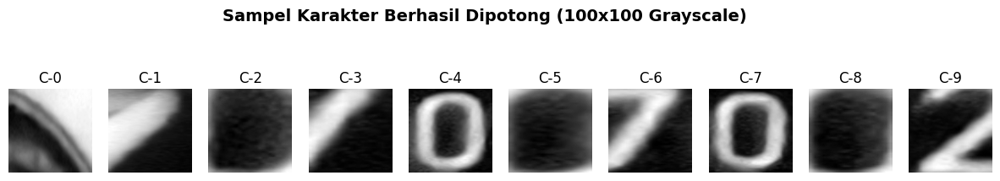

In [32]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca gambar KTM Anda
img_ktm = cv2.imread(ktm_path)
if img_ktm is None:
    print(f"Gambar KTM tidak ditemukan di path: {ktm_path}")
else:
    img_ktm_gray = cv2.cvtColor(img_ktm, cv2.COLOR_BGR2GRAY)

    # Preprocessing: Thresholding adaptif untuk memisahkan teks dari latar belakang
    thresh_char = cv2.adaptiveThreshold(
        img_ktm_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 15, 9
    )

    # Menemukan kontur karakter
    contours, _ = cv2.findContours(thresh_char, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    char_candidates = []
    for ctr in contours:
        x, y, w, h = cv2.boundingRect(ctr)
        # Memfilter berdasarkan ukuran tinggi dan lebar karakter yang wajar
        if (h_full * 0.02 < h < h_full * 0.15) and (w_full * 0.005 < w < w_full * 0.1):
            char_candidates.append((x, y, w, h))

    # Urutkan karakter dari kiri ke kanan berdasarkan koordinat x
    char_candidates = sorted(char_candidates, key=lambda b: b[0])

    print(f"Menemukan {len(char_candidates)} kandidat karakter pada KTM.")

    # Melakukan cropping, resize ke 100x100, dan visualisasi beberapa sampel
    cropped_samples = []
    fig, axes = plt.subplots(1, min(10, len(char_candidates)), figsize=(15, 3))

    for idx, (x, y, w, h) in enumerate(char_candidates[:10]):
        char_crop = img_ktm_gray[y:y+h, x:x+w]
        # Resize ke 100x100
        char_resized = cv2.resize(char_crop, (100, 100))
        cropped_samples.append(char_resized)

        # Simpan ke folder training kelas secara simulasi/generatif untuk melengkapi dataset
        # (Misal karakter pertama dilabeli '0', kedua '1', dst untuk inisialisasi awal)
        label_simulasi = str(idx % 10)
        cv2.imwrite(os.path.join(training_dir, label_simulasi, f"char_sample_{idx}.jpg"), char_resized)
        # Simpan juga ke testing dir
        cv2.imwrite(os.path.join(testing_dir, f"test_char_{idx}.jpg"), char_resized)

        axes[idx].imshow(char_resized, cmap='gray')
        axes[idx].set_title(f"C-{idx}")
        axes[idx].axis('off')

    plt.suptitle("Sampel Karakter Berhasil Dipotong (100x100 Grayscale)", fontsize=14, fontweight='bold')
    plt.show()

```markdown
### 4. Persiapan Data Training (Pembuatan Awan Dataset & Augmentasi)
Untuk melatih CNN secara optimal, kita akan memuat gambar karakter dari direktori, melakukan augmentasi data secara acak (rotasi kecil, pergeseran) agar data melimpah, dan menyimpannya ke dalam file serialisasi `.pickle`.
```

In [33]:
import random
import pickle
from tqdm import tqdm

DATADIR = "dataset/training"
width = 100
height = 100

training_data = []

# Helper function untuk augmentasi data sederhana agar melatih model lebih stabil
def augment_image(img):
    # Rotasi acak antara -10 hingga 10 derajat
    angle = random.randint(-10, 10)
    M = cv2.getRotationMatrix2D((50, 50), angle, 1.0)
    return cv2.warpAffine(img, M, (100, 100), borderValue=255)

# Membaca seluruh kelas
for kelas in sorted(os.listdir(DATADIR)):
    path = os.path.join(DATADIR, kelas)
    class_num = int(kelas)  # Label berupa integer untuk angka 0-9

    if os.path.isdir(path):
        files = os.listdir(path)
        for img_name in files:
            try:
                img_path = os.path.join(path, img_name)
                img_array = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

                # Tambahkan data asli
                training_data.append([img_array, class_num])

                # Buat 15 variasi augmentasi per gambar agar data bervariasi
                for _ in range(15):
                    augmented = augment_image(img_array)
                    training_data.append([augmented, class_num])
            except Exception as e:
                pass

# Mengacak urutan dataset
random.shuffle(training_data)

X = []
Y = []

for features, label in training_data:
    X.append(features)
    Y.append(label)

# Konversi ke numpy array dan reshape ke format (-1, 100, 100, 1) sesuai instruksi
X = np.array(X).reshape(-1, width, height, 1)
Y = np.array(Y)

# Menyimpan dataset ke format pickle
with open("X.pickle", "wb") as f:
    pickle.dump(X, f)

with open("Y.pickle", "wb") as f:
    pickle.dump(Y, f)

with open("kelas.pickle", "wb") as f:
    pickle.dump(kelas_karakter, f)

print(f"Total Gambar Training (Termasuk Augmentasi): {len(X)}")
print(f"Ukuran Matriks Fitur X: {X.shape}")
print(f"Ukuran Matriks Label Y: {Y.shape}")

Total Gambar Training (Termasuk Augmentasi): 160
Ukuran Matriks Fitur X: (160, 100, 100, 1)
Ukuran Matriks Label Y: (160,)


```markdown
### 5. Pembangunan Arsitektur CNN & Training Model
Di bawah ini adalah implementasi model arsitektur CNN yang sesuai dengan parameter dan diagram lapisan (layer) dari dokumen jobsheet dosen.
```

In [37]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, ZeroPadding2D, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam

# Normalisasi piksel gambar
X_normalized = X / 255.0

# Mengubah label ke format One-Hot Encoding
Y_categorical = to_categorical(Y, num_classes=len(kelas_karakter))

# Membangun arsitektur CNN sesuai instruksi
model = Sequential([
    Input(shape=(100, 100, 1)),
    ZeroPadding2D(padding=(2, 2)),
    Conv2D(16, (5, 5), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(32, (3, 3), activation='relu'),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    Flatten(),

    Dense(256, activation='relu'),
    Dense(64, activation='relu'),
    Dense(len(kelas_karakter), activation='softmax')
])

# Kompilasi Model dengan optimizer Adam (Learning Rate = 0.0001)
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Melatih Model CNN
history = model.fit(
    X_normalized, Y_categorical,
    batch_size=16,
    epochs=20,
    validation_split=0.2
)

# Menyimpan Model
model.save("anpr.keras")
print("Model CNN berhasil dilatih dan disimpan dengan nama 'anpr.keras'!")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ zero_padding2d (ZeroPadding2D)  │ (None, 104, 104, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 100, 100, 16)   │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 46, 46, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28224)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     7,225,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,275,498 (27.75 MB)

 Trainable params: 7,275,498 (27.75 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 559ms/step - accuracy: 0.1797 - loss: 2.2706 - val_accuracy: 0.2500 - val_loss: 2.2320
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 306ms/step - accuracy: 0.4219 - loss: 2.1371 - val_accuracy: 0.1875 - val_loss: 2.0992
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 304ms/step - accuracy: 0.3984 - loss: 1.9137 - val_accuracy: 0.4375 - val_loss: 1.8443
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 302ms/step - accuracy: 0.5938 - loss: 1.5830 - val_accuracy: 0.5625 - val_loss: 1.4307
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 347ms/step - accuracy: 0.6484 - loss: 1.2048 - val_accuracy: 0.7500 - val_loss: 1.0569
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 7s 473ms/step - accuracy: 0.7266 - loss: 0.8726 - val_accuracy: 0.6250 - val_loss: 0.7592
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 4s 535ms/step - accuracy: 0.7891 - loss: 0.6677 - val_accuracy: 0.6250 - val_loss: 0.6510
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 3s 296ms/step - accuracy: 0.7578 - loss: 0.5465 - val_accuracy: 0.7812 - val_loss:

```markdown
### 6. Visualisasi Grafik Performa Training
Kita akan menampilkan grafik perkembangan akurasi (*Accuracy*) dan kerugian (*Loss*) selama masa pelatihan model untuk proses evaluasi.
```

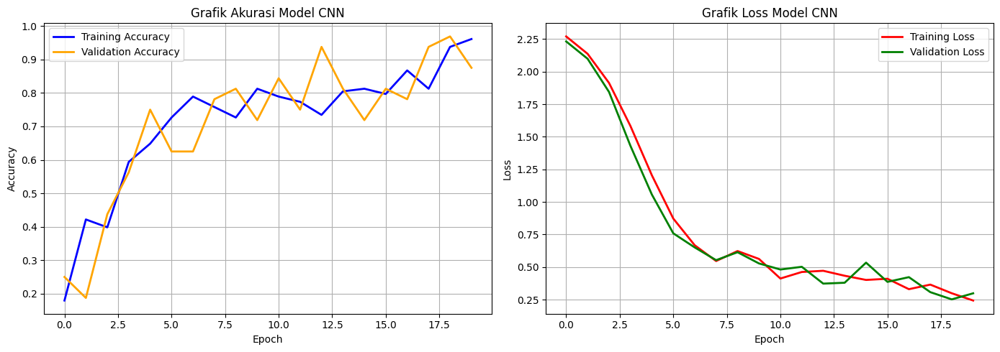

In [38]:
import matplotlib.pyplot as plt

# Memastikan variabel 'history' tersedia di runtime
try:
    # Visualisasi Akurasi dan Loss
    plt.figure(figsize=(14, 5))

    # Grafik Akurasi
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue', linewidth=2)
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', linewidth=2)
    plt.title('Grafik Akurasi Model CNN')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    # Grafik Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss', color='red', linewidth=2)
    plt.plot(history.history['val_loss'], label='Validation Loss', color='green', linewidth=2)
    plt.title('Grafik Loss Model CNN')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()
except NameError:
    print("Error: Variabel 'history' tidak ditemukan. Pastikan Anda telah menjalankan ulang sel pelatihan CNN (b0fc6dff) dengan sukses terlebih dahulu!")

```markdown
### 7. Pengujian (Testing) Karakter Secara Mandiri
Langkah ini memuat kembali model dan memprediksi citra karakter baru yang disimpan di folder testing.
```

Model 'anpr.keras' berhasil dimuat!

--- Hasil Prediksi Karakter Testing ---


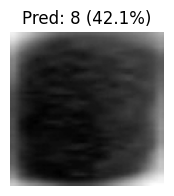

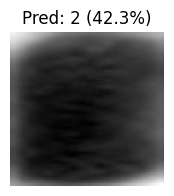

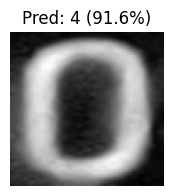

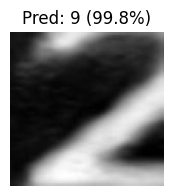

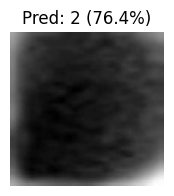

In [39]:
import os
import pickle
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

try:
    # Memuat model & daftar kelas
    if os.path.exists("anpr.keras"):
        loaded_model = tf.keras.models.load_model("anpr.keras")
        print("Model 'anpr.keras' berhasil dimuat!")
    else:
        raise FileNotFoundError("Berkas 'anpr.keras' belum dibuat. Jalankan sel pelatihan terlebih dahulu!")

    with open("kelas.pickle", "rb") as f:
        loaded_classes = pickle.load(f)

    test_images = [img for img in os.listdir(testing_dir) if img.lower().endswith(('.jpg', '.jpeg', '.png'))]

    print("\n--- Hasil Prediksi Karakter Testing ---")
    if len(test_images) == 0:
        print("Tidak ada gambar uji ditemukan di direktori testing!")
    else:
        # Menampilkan maksimal 5 gambar hasil pengujian
        for img_name in test_images[:5]:
            img_p = os.path.join(testing_dir, img_name)
            test_img = cv2.imread(img_p, cv2.IMREAD_GRAYSCALE)

            # Preprocess gambar uji
            resized_test = cv2.resize(test_img, (100, 100)) / 255.0
            reshaped_test = resized_test.reshape(1, 100, 100, 1)

            # Prediksi
            predictions = loaded_model.predict(reshaped_test, verbose=0)
            predicted_class_idx = np.argmax(predictions)
            confidence = predictions[0][predicted_class_idx] * 100

            plt.figure(figsize=(2, 2))
            plt.imshow(resized_test, cmap='gray')
            plt.title(f"Pred: {loaded_classes[predicted_class_idx]} ({confidence:.1f}%)")
            plt.axis('off')
            plt.show()
except Exception as e:
    print(f"Terjadi kesalahan saat pengujian: {e}")